#                                                           Titanic dataset analysis

## Importing libraries

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## Setting styles 

In [39]:
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [40]:
df = pd.read_csv("data/raw/train.csv")

In [41]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## Basic info

In [42]:
df.shape

(891, 12)

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [44]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [45]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Check missing values

In [46]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


## Data Cleaning

In [47]:
# Handle missing Age - fill with median by Pclass (there were 177 age were not given in the original data)
df['Age'] = df['Age'].fillna(df.groupby('Pclass')['Age'].transform('median'))

In [48]:
# Handle missing Embarked - fill with mode (filled with two blank data with mode (which is most repeated embarked name))
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [49]:
# Drop Cabin (too many missing values)
df = df.drop('Cabin', axis=1)

In [50]:
# Create new feature: Family Size
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

In [51]:
# Create age groups
df['AgeGroup'] = pd.cut(df['Age'], bins=[0, 12, 18, 35, 60, 80], 
                         labels=['Child', 'Teenager', 'Adult', 'Middle-aged', 'Senior'])

In [52]:
print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
FamilySize     0
AgeGroup       0
dtype: int64


## Statistical Analysis

In [53]:
# Overall survival rate
survival_rate = df['Survived'].mean() * 100
print(f"Overall Survival Rate: {survival_rate:.2f}%")

Overall Survival Rate: 38.38%


In [54]:
# Survival by gender (Chi-square test)
contingency_table = pd.crosstab(df['Sex'], df['Survived'])
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Gender vs Survival - Chi-square: {chi2:.4f}, p-value: {p_value:.4f}")

Gender vs Survival - Chi-square: 260.7170, p-value: 0.0000


In [55]:
# Survival by class (Chi-square test)
contingency_table_class = pd.crosstab(df['Pclass'], df['Survived'])
chi2_class, p_value_class, _, _ = stats.chi2_contingency(contingency_table_class)
print(f"Class vs Survival - Chi-square: {chi2_class:.4f}, p-value: {p_value_class:.4f}")

Class vs Survival - Chi-square: 102.8890, p-value: 0.0000


In [56]:
# Age comparison (T-test)
survived_ages = df[df['Survived'] == 1]['Age']
died_ages = df[df['Survived'] == 0]['Age']
t_stat, p_value_age = stats.ttest_ind(survived_ages, died_ages)
print(f"Age T-test - t-statistic: {t_stat:.4f}, p-value: {p_value_age:.4f}")

Age T-test - t-statistic: -1.4105, p-value: 0.1587


In [57]:
# Correlation matrix
correlation = df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']].corr()
print(correlation['Survived'].sort_values(ascending=False))

Survived      1.000000
Fare          0.257307
Parch         0.081629
FamilySize    0.016639
SibSp        -0.035322
Age          -0.047255
Pclass       -0.338481
Name: Survived, dtype: float64


In [58]:
# Defining children (under 18)
df['IsChild'] = (df['Age'] < 18).astype(int)

# Chi-square test
child_table = pd.crosstab(df['IsChild'], df['Survived'])
chi2, p_val, _, _ = stats.chi2_contingency(child_table)

In [59]:
# Calculating fare per person
df['FarePerPerson'] = df['Fare'] / df['FamilySize']

# Creating fare categories
df['FareCategory'] = pd.cut(df['FarePerPerson'], 
                              bins=[0, 10, 20, 50, 100, 600],
                              labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])

## Visualizations

### Overall survival 

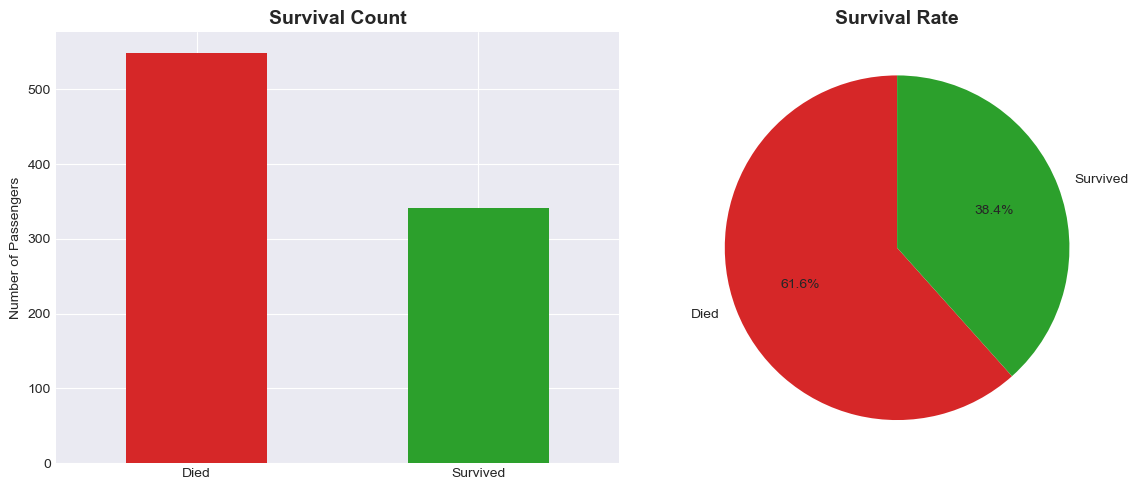

In [60]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Survival count
df['Survived'].value_counts().plot(kind='bar', ax=ax[0], color=['#d62728', '#2ca02c'])
ax[0].set_title('Survival Count', fontsize=14, fontweight='bold')
ax[0].set_xlabel('')
ax[0].set_ylabel('Number of Passengers')
ax[0].set_xticklabels(['Died', 'Survived'], rotation=0)

# Survival percentage
survival_pct = df['Survived'].value_counts(normalize=True) * 100
survival_pct.plot(kind='pie', ax=ax[1], autopct='%1.1f%%', startangle=90, 
                   colors=['#d62728', '#2ca02c'], labels=['Died', 'Survived'])
ax[1].set_title('Survival Rate', fontsize=14, fontweight='bold')
ax[1].set_ylabel('')

plt.tight_layout()
plt.savefig('visuals/overall_survival.png', dpi=300, bbox_inches='tight')
plt.show()

### Survival by gender 


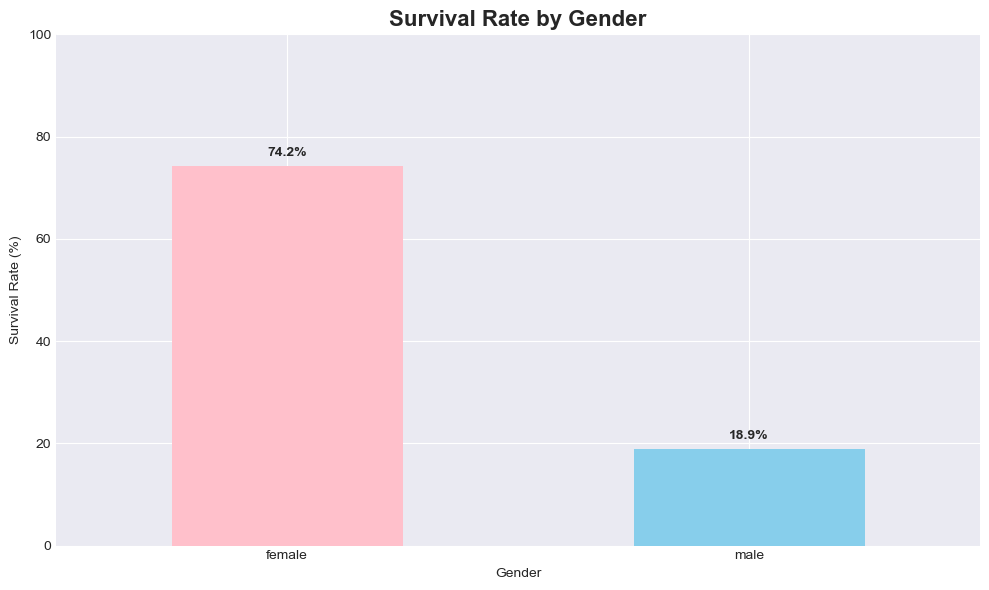

In [61]:
plt.figure(figsize=(10, 6))

survival_by_gender = df.groupby('Sex')['Survived'].mean() * 100
survival_by_gender.plot(kind='bar', color=['pink', 'skyblue'])
plt.title('Survival Rate by Gender', fontsize=16, fontweight='bold')
plt.xlabel('Gender')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)

# Adding value labels on bars
for i, v in enumerate(survival_by_gender):
    plt.text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('visuals/survival_by_gender.png', dpi=300, bbox_inches='tight')
plt.show()

### Survival by Class

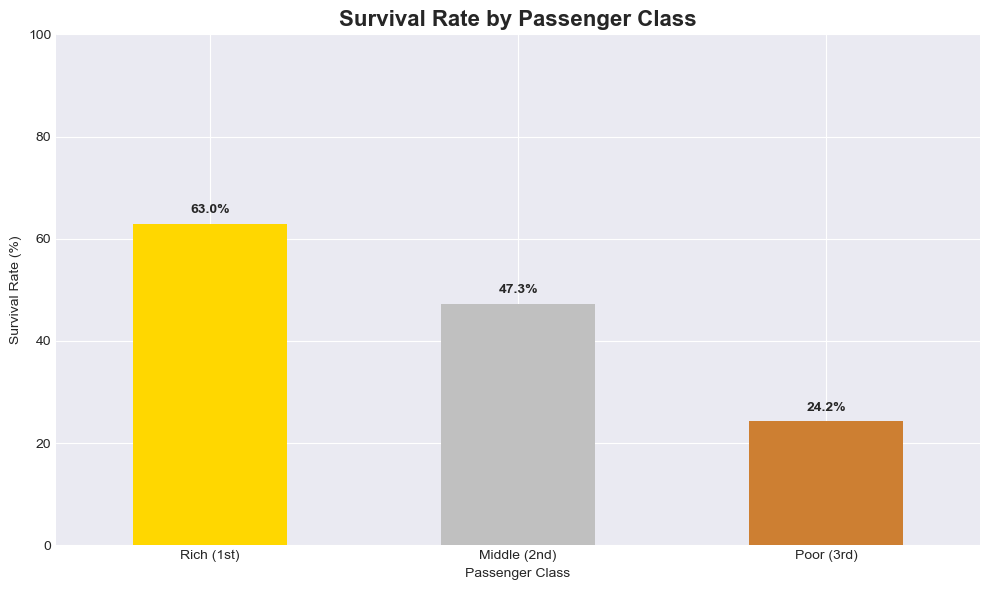

In [62]:
plt.figure(figsize=(10, 6))
survival_by_class = df.groupby('Pclass')['Survived'].mean() * 100
survival_by_class.plot(kind='bar', color=['gold', 'silver', '#CD7F32'])
plt.title('Survival Rate by Passenger Class', fontsize=16, fontweight='bold')
plt.xticks(ticks=[0, 1, 2], labels=['Rich (1st)', 'Middle (2nd)', 'Poor (3rd)'], rotation=0)
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate (%)')
plt.ylim(0, 100)

for i, v in enumerate(survival_by_class):
    plt.text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('visuals/survival_by_class.png', dpi=300, bbox_inches='tight')
plt.show()

### Age distribution

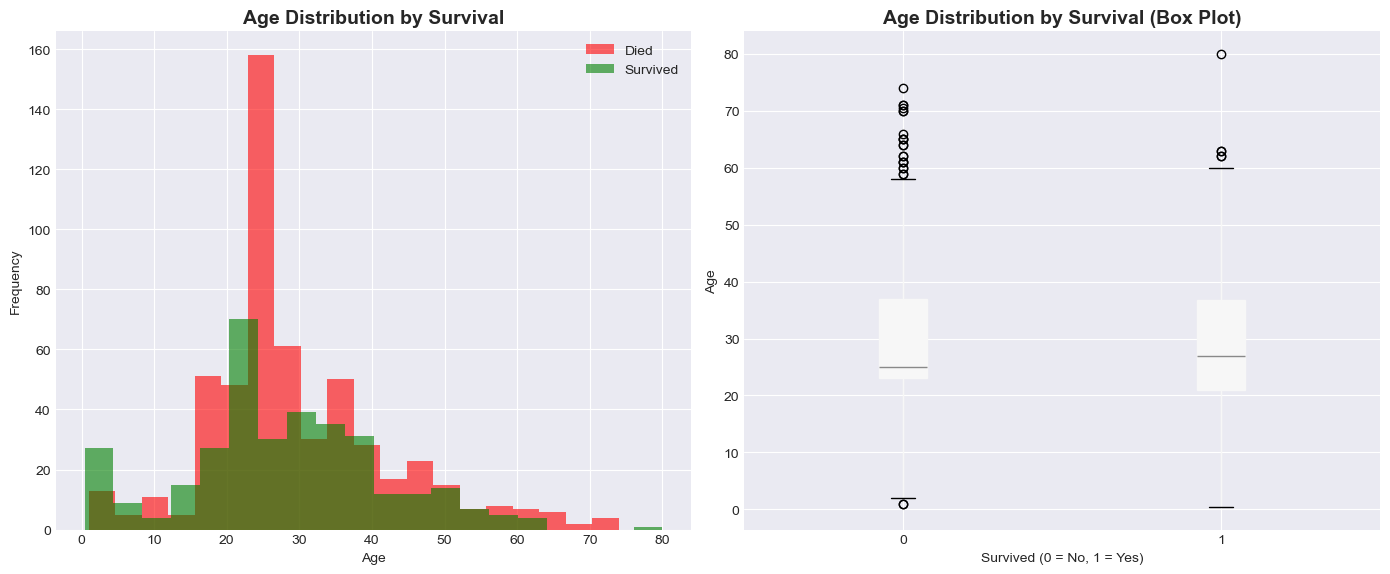

In [63]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Histogram
df[df['Survived'] == 0]['Age'].hist(bins=20, alpha=0.6, label='Died', ax=ax[0], color='red')
df[df['Survived'] == 1]['Age'].hist(bins=20, alpha=0.6, label='Survived', ax=ax[0], color='green')
ax[0].set_title('Age Distribution by Survival', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Age')
ax[0].set_ylabel('Frequency')
ax[0].legend()

# Box plot
df.boxplot(column='Age', by='Survived', ax=ax[1], patch_artist=True)
ax[1].set_title('Age Distribution by Survival (Box Plot)', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Survived (0 = No, 1 = Yes)')
ax[1].set_ylabel('Age')

plt.suptitle('')
plt.tight_layout()
plt.savefig('visuals/age_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

### Heatmap of Correlations

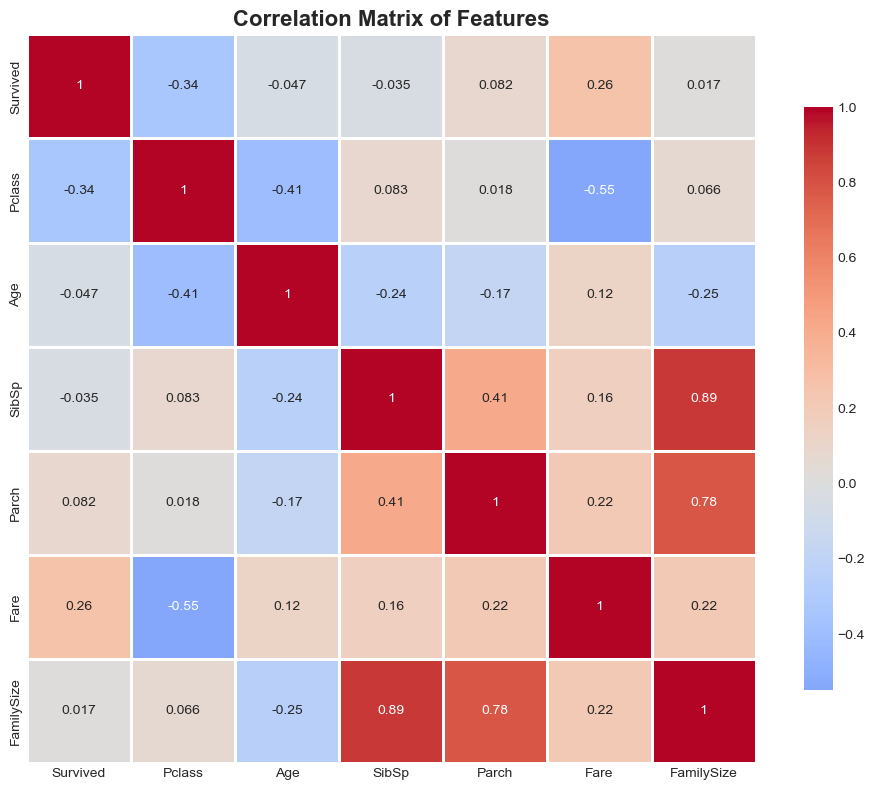

In [64]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix of Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('visuals/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### Survival by Gender and Class

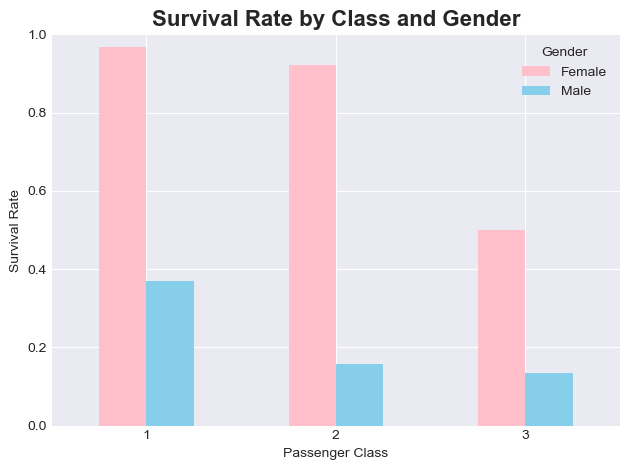

In [65]:
survival_gender_class = df.groupby(['Pclass', 'Sex'])['Survived'].mean().unstack()
survival_gender_class.plot(kind='bar', color=['pink', 'skyblue'])
plt.title('Survival Rate by Class and Gender', fontsize=16, fontweight='bold')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.legend(title='Gender', labels=['Female', 'Male'])
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig('visuals/survival_gender_class.png', dpi=300, bbox_inches='tight')
plt.show()

### Survival Rate by Fare Per Person

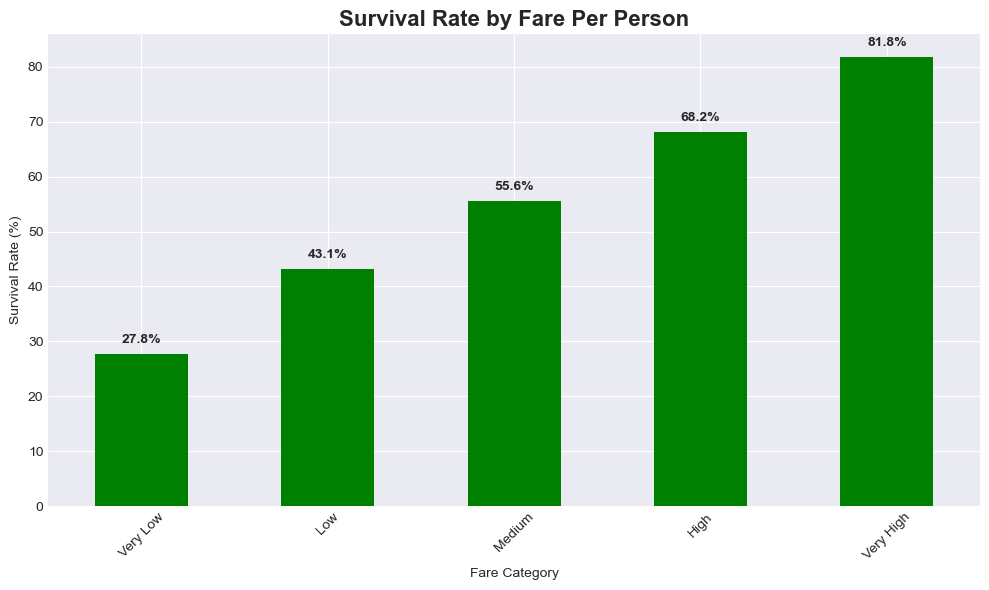

In [66]:
fare_survival = df.groupby('FareCategory', observed=False)['Survived'].mean() * 100
fare_survival.plot(kind='bar', figsize=(10, 6), color='green')
plt.title('Survival Rate by Fare Per Person', fontsize=16, fontweight='bold')
plt.ylabel('Survival Rate (%)')
plt.xlabel('Fare Category')
plt.xticks(rotation=45)

# Adding value labels
for i, v in enumerate(fare_survival):
    if not pd.isna(v):  # Checking if value exists
        plt.text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('visuals/survival_fare_per_person.png', dpi=300, bbox_inches='tight')
plt.show()

### Childeren vs Adults Survival Comparison

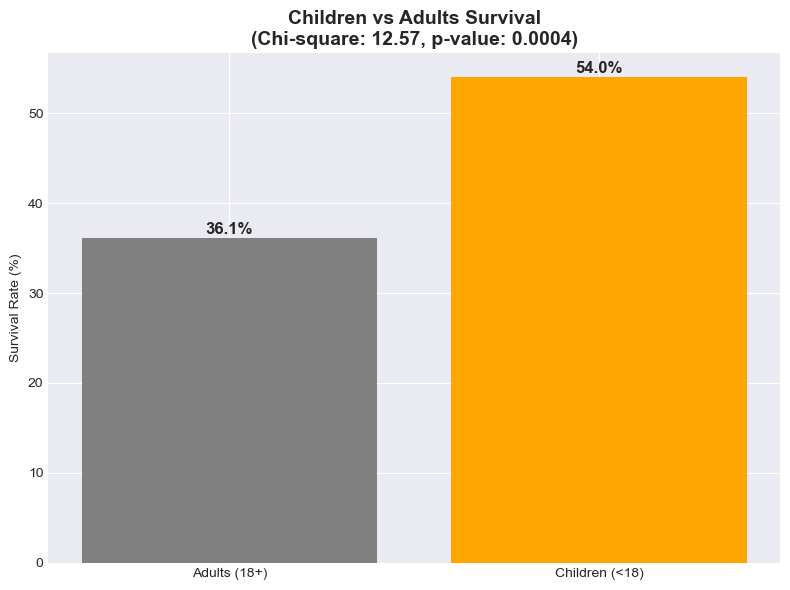

In [67]:
# Visualization
child_survival = df.groupby('IsChild')['Survived'].mean() * 100

plt.figure(figsize=(8, 6))
bars = plt.bar(['Adults (18+)', 'Children (<18)'], child_survival, color=['gray', 'orange'])
plt.title(f'Children vs Adults Survival\n(Chi-square: {chi2:.2f}, p-value: {p_val:.4f})', 
          fontsize=14, fontweight='bold')
plt.ylabel('Survival Rate (%)')
for bar, val in zip(bars, child_survival):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.5, f'{val:.1f}%', 
             ha='center', fontweight='bold', fontsize=12)
    
plt.savefig('visuals/survival_fare_per_person.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()